In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mygene

In [2]:
res = pd.read_csv("../results/deseq2_flight_vs_ground.csv")
vst = pd.read_csv("../results/vst_counts.csv", index_col=0)
samples = pd.read_csv("../data/samples.csv")

print(res.shape)
res.head()

(16054, 8)


,gene_id,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,log2FC_shrunk
0,ENSMUSG00000038216,525.829282,4.001663,0.153007,26.153440,9.006133e-151,1.445845e-146,3.982831
1,ENSMUSG00000015357,4353.238291,0.944602,0.063328,14.916007,2.593349e-50,2.081681e-46,0.936498
2,ENSMUSG00000004939,7196.592228,-3.923078,0.322213,-12.175435,4.201458e-34,2.248340e-30,-3.867932
3,ENSMUSG00000038518,1439.341936,-0.852033,0.070285,-12.122606,8.016846e-34,3.217561e-30,-0.841143
4,ENSMUSG00000001552,2302.115107,1.083097,0.089687,12.076391,1.407630e-33,4.519618e-30,1.069114


In [3]:
mg = mygene.MyGeneInfo()
hits = mg.querymany(
    res["gene_id"].tolist(),
    scopes="ensembl.gene",
    fields="symbol,name",
    species="mouse",
    as_dataframe=True,
    verbose=False,
)
hits = hits[~hits.index.duplicated(keep="first")]   # keep one match per ID

res["symbol"] = res["gene_id"].map(hits["symbol"])
res["name"] = res["gene_id"].map(hits["name"])
print("Genes without a symbol:", res["symbol"].isna().sum())

res["symbol"] = res["symbol"].fillna(res["gene_id"])   # use the ID if no symbol found
res.to_csv("../results/deseq2_annotated.csv", index=False)

Genes without a symbol: 47


In [4]:
sig = res["padj"] < 0.05
up = sig & (res["log2FC_shrunk"] > 1)
down = sig & (res["log2FC_shrunk"] < -1)

print(f"Significant (padj < 0.05): {sig.sum():,}")
print(f"Significant AND at least 2x change: {(up | down).sum():,}")
print(f"  Up in Flight (>2x):   {up.sum():,}")
print(f"  Down in Flight (>2x): {down.sum():,}")

Significant (padj < 0.05): 4,234
Significant AND at least 2x change: 306
  Up in Flight (>2x):   160
  Down in Flight (>2x): 146


In [5]:
top20 = res[sig].nsmallest(20, "padj")[["symbol", "name", "log2FC_shrunk", "padj"]]
top20

,symbol,name,log2FC_shrunk,padj
0,Pnmt,phenylethanolamine-N-methyltransferase,3.982831,1.445845e-146
1,Clpx,caseinolytic mitochondrial matrix peptidase ch...,0.936498,2.081681e-46
2,Nmrk2,nicotinamide riboside kinase 2,-3.867932,2.248340e-30
3,Jarid2,jumonji and AT-rich interaction domain contain...,-0.841143,3.217561e-30
4,Jup,junction plakoglobin,1.069114,4.519618e-30
5,Lcn2,lipocalin 2,3.777608,3.769127e-27
6,Gm35546,"predicted gene, 35546",-1.854405,3.769127e-27
7,Gucd1,guanylyl cyclase domain containing 1,0.923167,3.607671e-26
8,Gm43672,predicted gene 43672,1.112539,1.048581e-24
9,Fkbp5,FK506 binding protein 5,1.344247,6.877287e-23


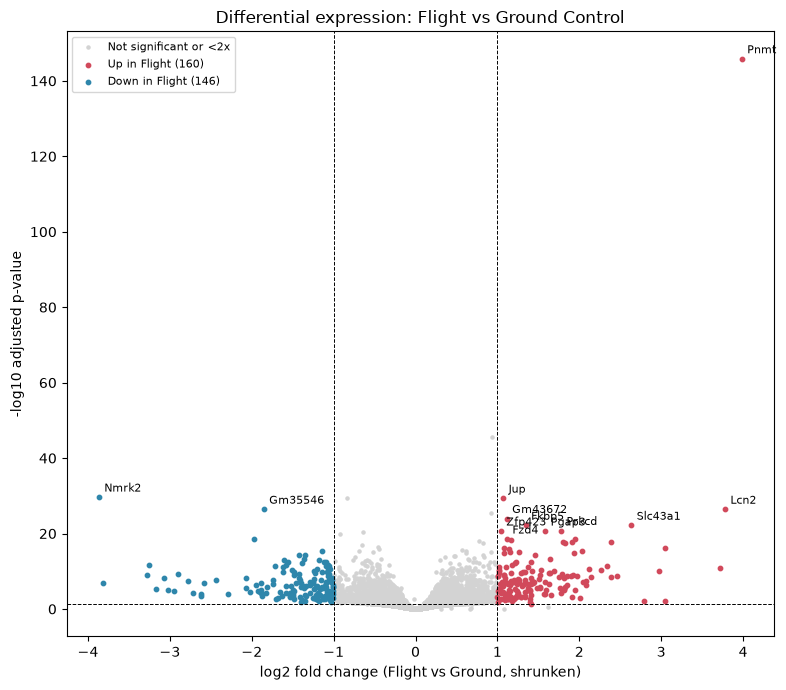

In [6]:
res_plot = res.dropna(subset=["padj"]).copy()
res_plot["neglog10_padj"] = -np.log10(res_plot["padj"].clip(lower=1e-300))
up_p = (res_plot["padj"] < 0.05) & (res_plot["log2FC_shrunk"] > 1)
down_p = (res_plot["padj"] < 0.05) & (res_plot["log2FC_shrunk"] < -1)
other = ~(up_p | down_p)

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(res_plot.loc[other, "log2FC_shrunk"], res_plot.loc[other, "neglog10_padj"],
           s=5, c="lightgrey", label="Not significant or <2x")
ax.scatter(res_plot.loc[up_p, "log2FC_shrunk"], res_plot.loc[up_p, "neglog10_padj"],
           s=10, c="#d1495b", label=f"Up in Flight ({up_p.sum()})")
ax.scatter(res_plot.loc[down_p, "log2FC_shrunk"], res_plot.loc[down_p, "neglog10_padj"],
           s=10, c="#2e86ab", label=f"Down in Flight ({down_p.sum()})")

for _, row in res_plot[up_p | down_p].nsmallest(12, "padj").iterrows():
    ax.annotate(row["symbol"], (row["log2FC_shrunk"], row["neglog10_padj"]),
                fontsize=8, xytext=(4, 4), textcoords="offset points")

ax.axhline(-np.log10(0.05), ls="--", c="k", lw=0.7)
ax.axvline(1, ls="--", c="k", lw=0.7)
ax.axvline(-1, ls="--", c="k", lw=0.7)
ax.set_xlabel("log2 fold change (Flight vs Ground, shrunken)")
ax.set_ylabel("-log10 adjusted p-value")
ax.set_title("Differential expression: Flight vs Ground Control")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("../figures/04_volcano.png", dpi=200)
plt.show()

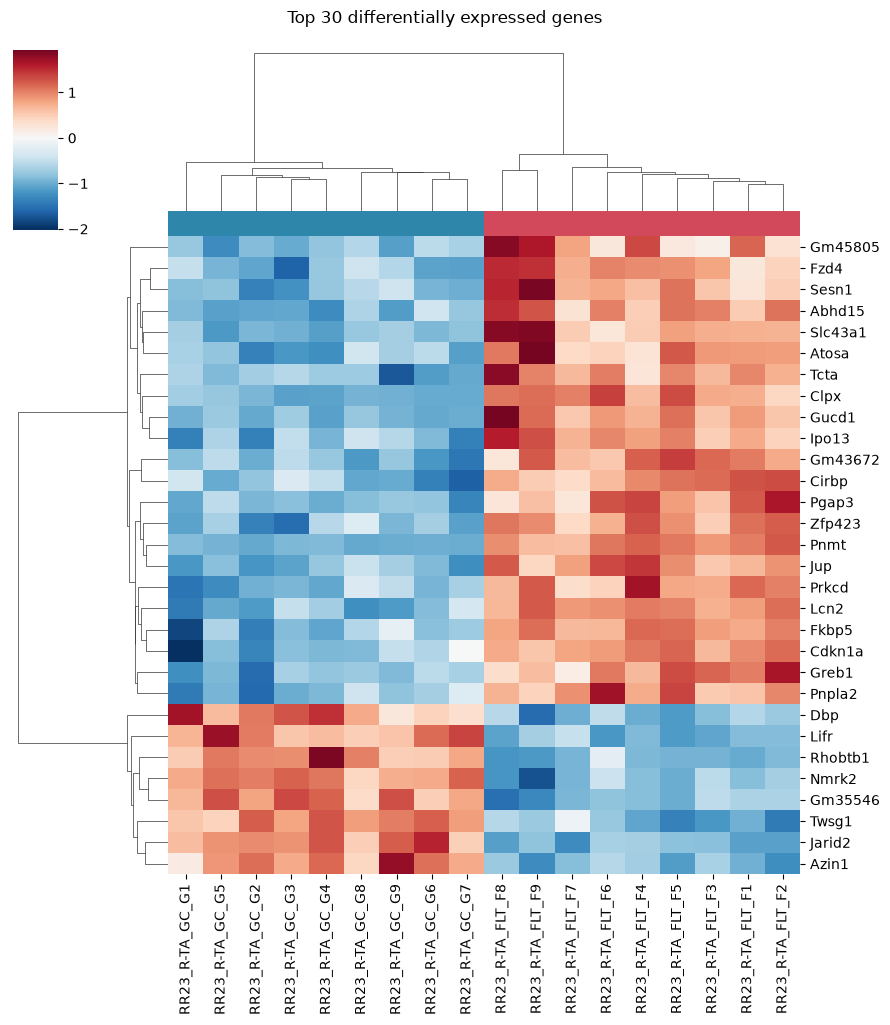

In [7]:
top30 = res[sig].nsmallest(30, "padj")
mat = vst.loc[top30["gene_id"], samples["sample"]]
mat.index = top30["symbol"].values

z = mat.sub(mat.mean(axis=1), axis=0).div(mat.std(axis=1), axis=0)   # z-score each gene
col_colors = samples["condition"].map({"Flight": "#d1495b", "Ground": "#2e86ab"}).values

g = sns.clustermap(z, cmap="RdBu_r", center=0, col_colors=col_colors,
                   figsize=(9, 10), yticklabels=True, xticklabels=True)
g.fig.suptitle("Top 30 differentially expressed genes", y=1.02)
g.savefig("../figures/05_top_genes_heatmap.png", dpi=200)
plt.show()